# Crowd Management — YOLO Person Detection, Tracking & Counting

This Google Colab notebook implements:

**CVAT person dataset → YOLO dataset → training → validation → detection → ByteTrack → persistent PERSON IDs → crowd counting**

The camera pipeline uses anonymous person IDs such as `PERSON1`, `PERSON2`, etc. It does not infer gender from camera appearance.

In [1]:
!pip -q install -U ultralytics opencv-python-headless pyyaml lxml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 130.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 9.3 MB/s eta 0:00:00


## 1. Upload your dataset

Upload `archive.zip`, the CVAT/person dataset supplied for this project.

In [2]:
from google.colab import files
import glob, os

uploaded = files.upload()

zip_candidates = glob.glob("/content/*.zip")
if not zip_candidates:
    raise FileNotFoundError("No ZIP file found. Upload archive.zip first.")

ZIP_PATH = zip_candidates[0]
print("Using:", ZIP_PATH)

Saving archive.zip to archive.zip
Using: /content/archive.zip


## 2. Extract the ZIP

In [3]:
import zipfile, os, shutil

RAW_DIR = "/content/raw_dataset"

if os.path.exists(RAW_DIR):
    shutil.rmtree(RAW_DIR)

os.makedirs(RAW_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(RAW_DIR)

for root, dirs, files_ in os.walk(RAW_DIR):
    level = root.replace(RAW_DIR, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for f in files_[:10]:
            print("  " * (level + 1) + f)

raw_dataset/
  annotations.xml
  boxes/
    frame_000030.PNG
    frame_000021.PNG
    frame_000006.PNG
    frame_000015.PNG
    frame_000025.PNG
    frame_000040.PNG
    frame_000018.PNG
    frame_000026.PNG
    frame_000000.PNG
    frame_000033.PNG
  images/
    frame_000030.PNG
    frame_000021.PNG
    frame_000006.PNG
    frame_000015.PNG
    frame_000025.PNG
    frame_000040.PNG
    frame_000018.PNG
    frame_000026.PNG
    frame_000000.PNG
    frame_000033.PNG


## 3. Locate CVAT XML and image files

In [4]:
import glob, os

xml_files = glob.glob(RAW_DIR + "/**/*.xml", recursive=True)
image_files = glob.glob(RAW_DIR + "/**/*", recursive=True)

image_files = [
    p for p in image_files
    if os.path.splitext(p)[1].lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

if not xml_files:
    raise FileNotFoundError("No XML annotation file was found.")

if not image_files:
    raise FileNotFoundError("No image files were found.")

XML_FILE = xml_files[0]

print("XML:", XML_FILE)
print("Images:", len(image_files))

XML: /content/raw_dataset/annotations.xml
Images: 82


## 4. Convert CVAT tracking annotations to YOLO detection labels

The source XML uses `xtl, ytl, xbr, ybr`.

YOLO requires:

`class x_center y_center width height`

Class `0` is `person`.

In [5]:
import xml.etree.ElementTree as ET
from collections import defaultdict
from PIL import Image
import os, shutil

tree = ET.parse(XML_FILE)
root = tree.getroot()

frame_to_image = {}

for p in image_files:
    base = os.path.basename(p)
    stem = os.path.splitext(base)[0]
    digits = "".join(ch for ch in stem if ch.isdigit())
    if digits:
        frame_to_image[int(digits)] = p

sample_img = Image.open(next(iter(frame_to_image.values())))
WIDTH, HEIGHT = sample_img.size

annotations = defaultdict(list)

for track in root.findall(".//track"):
    if track.attrib.get("label", "").lower() != "person":
        continue

    for box in track.findall("box"):
        frame = int(box.attrib["frame"])

        xtl = float(box.attrib["xtl"])
        ytl = float(box.attrib["ytl"])
        xbr = float(box.attrib["xbr"])
        ybr = float(box.attrib["ybr"])

        xtl = max(0, min(WIDTH, xtl))
        xbr = max(0, min(WIDTH, xbr))
        ytl = max(0, min(HEIGHT, ytl))
        ybr = max(0, min(HEIGHT, ybr))

        bw = xbr - xtl
        bh = ybr - ytl

        if bw <= 1 or bh <= 1:
            continue

        xc = ((xtl + xbr) / 2) / WIDTH
        yc = ((ytl + ybr) / 2) / HEIGHT
        nw = bw / WIDTH
        nh = bh / HEIGHT

        annotations[frame].append(
            f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}"
        )

print("Image size:", WIDTH, "x", HEIGHT)
print("Annotated frames:", len(annotations))
print("Total person boxes:", sum(len(v) for v in annotations.values()))

Image size: 1280 x 720
Annotated frames: 41
Total person boxes: 1785


## 5. Create train / validation / test splits

Because the source is a video sequence, this uses a chronological split rather than a random split. For a stronger final model, add independent Kaggle crowd scenes and independent test videos.

In [6]:
YOLO_DIR = "/content/yolo_dataset"

if os.path.exists(YOLO_DIR):
    shutil.rmtree(YOLO_DIR)

for split in ["train", "val", "test"]:
    os.makedirs(f"{YOLO_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_DIR}/labels/{split}", exist_ok=True)

frames = sorted(annotations.keys())
n = len(frames)

if n < 10:
    raise ValueError(f"Only {n} annotated frames found.")

train_end = max(1, int(n * 0.70))
val_end = max(train_end + 1, int(n * 0.85))
val_end = min(val_end, n - 1)

splits = {
    "train": frames[:train_end],
    "val": frames[train_end:val_end],
    "test": frames[val_end:]
}

for split, frame_list in splits.items():
    for frame in frame_list:
        src = frame_to_image[frame]
        image_name = os.path.basename(src)

        dst_img = f"{YOLO_DIR}/images/{split}/{image_name}"
        dst_lbl = f"{YOLO_DIR}/labels/{split}/{os.path.splitext(image_name)[0]}.txt"

        shutil.copy2(src, dst_img)

        with open(dst_lbl, "w") as f:
            f.write("\n".join(annotations[frame]))

    print(split, len(frame_list), "frames")

DATA_YAML = f"""path: {YOLO_DIR}
train: images/train
val: images/val
test: images/test

names:
  0: person
"""

with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(DATA_YAML)

print(DATA_YAML)

train 28 frames
val 6 frames
test 7 frames
path: /content/yolo_dataset
train: images/train
val: images/val
test: images/test

names:
  0: person



## 6. Visual check of converted bounding boxes

Do this before training.

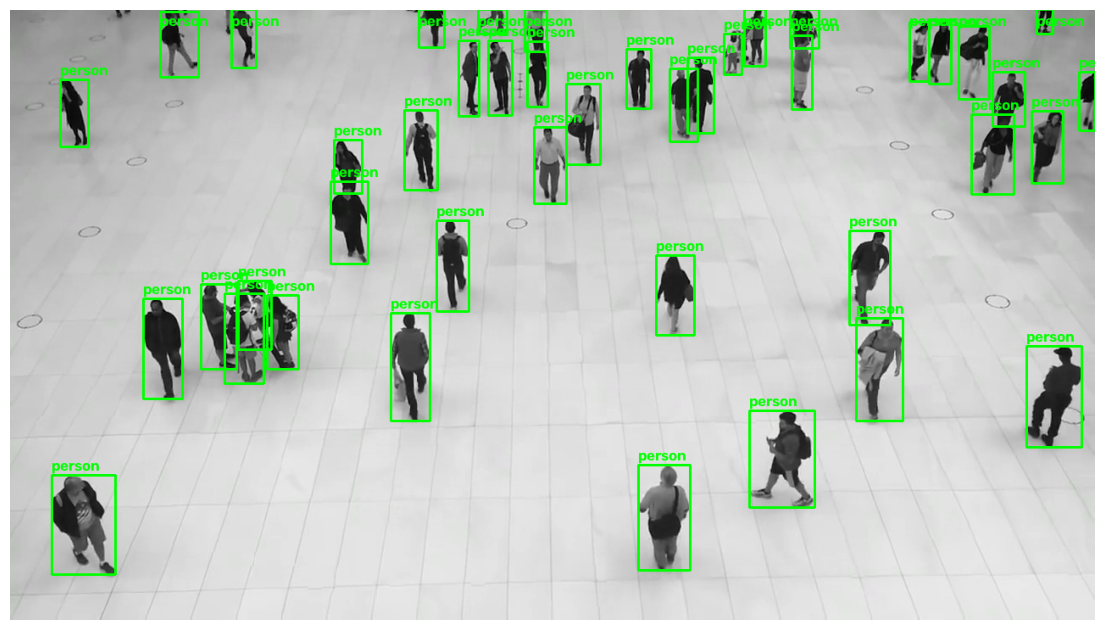

In [7]:
import cv2, random, matplotlib.pyplot as plt

def show_sample(image_path, label_path):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    if os.path.exists(label_path):
        with open(label_path) as f:
            lines = [x.strip() for x in f if x.strip()]

        for line in lines:
            cls, xc, yc, bw, bh = map(float, line.split())

            x1 = int((xc - bw/2) * w)
            y1 = int((yc - bh/2) * h)
            x2 = int((xc + bw/2) * w)
            y2 = int((yc + bh/2) * h)

            cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(img, "person", (x1, max(20,y1-5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

    plt.figure(figsize=(14,8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

train_images = glob.glob(f"{YOLO_DIR}/images/train/*")
sample = random.choice(train_images)
label = f"{YOLO_DIR}/labels/train/{os.path.splitext(os.path.basename(sample))[0]}.txt"

show_sample(sample, label)

## 7. Train YOLO

Start with YOLO11n for a lightweight Jetson-friendly baseline.

In [9]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{YOLO_DIR}/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    patience=20,
    project="/content/runs",
    name="crowd_person_detector",
    exist_ok=True
)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=crowd_person_detector, nbs=64, nms=None, ops

## 8. Load and validate the best model

In [10]:
BEST_MODEL = "/content/runs/crowd_person_detector/weights/best.pt"

if not os.path.exists(BEST_MODEL):
    raise FileNotFoundError(BEST_MODEL)

trained_model = YOLO(BEST_MODEL)

metrics = trained_model.val(
    data=f"{YOLO_DIR}/data.yaml",
    imgsz=640,
    device=0
)

print("Best model:", BEST_MODEL)

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4690.3±1457.9 MB/s, size: 854.0 KB)
val: Scanning /content/yolo_dataset/labels/val.cache... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6 1.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.5it/s 0.3s
                   all          6        258      0.986      0.965      0.993      0.822
Speed: 0.3ms preprocess, 14.1ms inference, 0.0ms loss, 4.6ms postprocess per image
Results saved to /content/runs/detect/val
Best model: /content/runs/crowd_person_detector/weights/best.pt


## 9. Run detection on the held-out test set

In [11]:
test_results = trained_model.predict(
    source=f"{YOLO_DIR}/images/test",
    conf=0.35,
    imgsz=640,
    save=True,
    project="/content/runs",
    name="test_predictions",
    exist_ok=True
)

print("Saved to /content/runs/test_predictions")


image 1/7 /content/yolo_dataset/images/test/frame_000034.PNG: 384x640 47 persons, 7.6ms
image 2/7 /content/yolo_dataset/images/test/frame_000035.PNG: 384x640 48 persons, 12.7ms
image 3/7 /content/yolo_dataset/images/test/frame_000036.PNG: 384x640 46 persons, 11.4ms
image 4/7 /content/yolo_dataset/images/test/frame_000037.PNG: 384x640 51 persons, 11.3ms
image 5/7 /content/yolo_dataset/images/test/frame_000038.PNG: 384x640 51 persons, 11.1ms
image 6/7 /content/yolo_dataset/images/test/frame_000039.PNG: 384x640 50 persons, 11.0ms
image 7/7 /content/yolo_dataset/images/test/frame_000040.PNG: 384x640 45 persons, 9.7ms
Speed: 3.2ms preprocess, 10.7ms inference, 1.7ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/test_predictions
Saved to /content/runs/test_predictions


## 10. Track people in a video

Set `VIDEO_PATH` to an MP4/video file. The tracker maintains persistent IDs and the code converts them to `PERSON1`, `PERSON2`, etc.

In [12]:
VIDEO_PATH = None  # Example: "/content/crowd_video.mp4"

from ultralytics import YOLO
import cv2

def track_video(video_path, output_path="/content/crowd_tracked.mp4"):
    model = YOLO(BEST_MODEL)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError("Could not open video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 25

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    person_names = {}
    seen_ids = set()

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[0],
            conf=0.35,
            imgsz=640,
            verbose=False
        )

        result = results[0]
        current_count = 0

        if result.boxes.id is not None:
            ids = result.boxes.id.int().cpu().tolist()
            boxes = result.boxes.xyxy.cpu().numpy()

            current_count = len(ids)

            for track_id, box in zip(ids, boxes):
                if track_id not in person_names:
                    person_names[track_id] = f"PERSON{len(person_names)+1}"

                seen_ids.add(track_id)
                name = person_names[track_id]

                x1, y1, x2, y2 = map(int, box)

                cv2.rectangle(frame, (x1,y1), (x2,y2), (0,255,0), 2)
                cv2.putText(
                    frame, name, (x1, max(25,y1-8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65,
                    (0,255,0), 2
                )

        cv2.rectangle(frame, (0,0), (380,100), (0,0,0), -1)

        cv2.putText(
            frame, f"CURRENT PEOPLE: {current_count}",
            (15,35), cv2.FONT_HERSHEY_SIMPLEX, 0.75,
            (255,255,255), 2
        )

        cv2.putText(
            frame, f"UNIQUE OBSERVED: {len(seen_ids)}",
            (15,72), cv2.FONT_HERSHEY_SIMPLEX, 0.75,
            (255,255,255), 2
        )

        writer.write(frame)

    cap.release()
    writer.release()
    return output_path

if VIDEO_PATH:
    print(track_video(VIDEO_PATH))
else:
    print("Set VIDEO_PATH first.")

Set VIDEO_PATH first.


## 11. Download `best.pt`

Copy this model to the Jetson Orin Nano for deployment.

In [13]:
from google.colab import files
files.download(BEST_MODEL)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Jetson Orin Nano runtime

After copying `best.pt` to the Jetson, use a USB camera with `cv2.VideoCapture(0)` and the same tracking logic.

For the final deployment, export/benchmark a TensorRT engine on the Jetson. Measure FPS and detection/counting accuracy at the actual camera resolution.

### Crowd-management outputs

- Current people
- Persistent person IDs
- Unique people observed
- Entry count
- Exit count
- Zone counts
- Crowd density
- Capacity/over-capacity alerts

The separate `gender_classification_v7.csv` is not used by this detector because it is a tabular gender-classification dataset and is not linked to the camera bounding boxes. The camera pipeline therefore does not infer gender from appearance.